In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from itertools import permutations
import matplotlib as mpl
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch

from ou_hankel import (OUNetwork,
                       empirical_kalman_causality_probability)
import pandas as pd

plt.rcParams.update({
    # Font Family
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    
    # Consistent Font Sizes
    'font.size': 13,          # Base default text size
    'axes.labelsize': 13,     # X and Y axis labels
    'axes.titlesize': 13,     # Subplot titles
    'xtick.labelsize': 13,    # X-axis tick labels
    'ytick.labelsize': 13,    # Y-axis tick labels
    'legend.fontsize': 10,   # Legend text
    'figure.titlesize': 10,   # Overall figure title
})

df = pd.read_csv("Binance/processed/vars_top10_1h.csv")
df["time"] = pd.to_datetime(df["time"])
df = df.set_index("time")
df = df[["coin", "p"]].pivot(columns='coin', values='p')


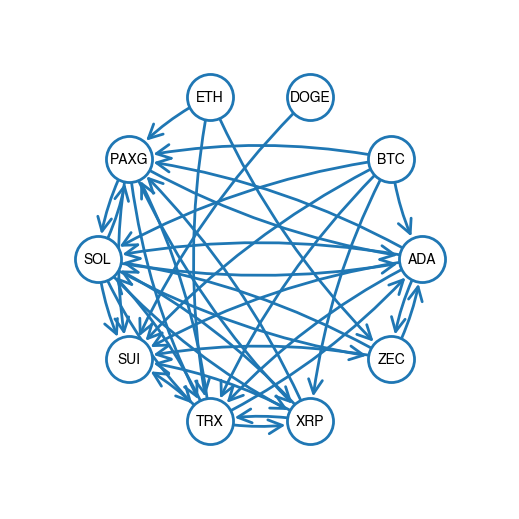

In [2]:
L = 8
nodes = list(df.columns)
X = df.to_numpy()

results = [(nodes[i], nodes[j], empirical_kalman_causality_probability(X, [i], [j], L)["log_odds"])for i, j in permutations(range(len(nodes)), 2)]
results_df = pd.DataFrame(results, columns=["Cause", "Target", "LogOdds"])
edges = list(results_df[results_df["LogOdds"] > 0][["Cause", "Target"]].itertuples(index=False, name=None))
G = nx.DiGraph()
G.add_nodes_from(nodes)
pos = nx.circular_layout(G)

fig, ax = plt.subplots(figsize=(5, 5))

nx.draw_networkx_nodes(
    G, pos,
    node_size=1100,
    node_color="white",
    edgecolors="tab:blue",
    linewidths=2,
    ax=ax
)

nx.draw_networkx_labels(
    G, pos,
    labels={n: n.replace("USDT", "") for n in nodes},
    font_weight="normal",
    font_color="black",
    font_size= 10,
    ax=ax
)

nx.draw_networkx_edges(
    G, pos,
    edgelist=edges,
    edge_color="tab:blue",
    width=2,
    arrowsize=25,
    arrowstyle="->",
    connectionstyle="arc3,rad=0.1",
    node_size=1100,
    min_source_margin=12,
    min_target_margin=18,
    ax=ax
)

ax.set_facecolor("white")
ax.margins(.20)
ax.axis("off")

plt.tight_layout(pad=0)
plt.savefig("plots/Figure5.pdf", bbox_inches="tight")
plt.show()

In [3]:
df

coin,ADAUSDT,BTCUSDT,DOGEUSDT,ETHUSDT,PAXGUSDT,SOLUSDT,SUIUSDT,TRXUSDT,XRPUSDT,ZECUSDT
time,,,,,,,,,,
2025-08-28 15:00:00,0.016605,1979.596597,0.003915,58.344121,8.592954,3.999686,0.066437,0.001314,0.067098,-7.450652
2025-08-28 16:00:00,0.014592,1731.672434,0.003659,46.636764,10.016590,2.431389,0.057578,-0.000038,0.053911,-6.914009
2025-08-28 17:00:00,0.015978,1814.600835,0.004745,58.346125,15.841276,3.520163,0.074997,0.000011,0.067532,-7.962798
2025-08-28 18:00:00,0.015011,1706.384576,0.004350,51.936263,15.217551,3.963222,0.070267,-0.000134,0.058428,-8.614518
2025-08-28 19:00:00,0.009902,1519.556620,0.002891,30.943271,10.252929,3.033914,0.048822,-0.000752,0.047411,-6.926013
...,...,...,...,...,...,...,...,...,...,...
2026-08-28 10:00:00,-0.011652,-2334.018605,-0.003490,-73.851523,-45.511607,-0.419532,-0.029921,0.000051,-0.092202,-48.150960
2026-08-28 11:00:00,-0.010359,-2124.057787,-0.003257,-68.850093,-57.992820,-0.167537,-0.026743,0.000040,-0.084364,-44.111473
2026-08-28 12:00:00,-0.011584,-2230.696191,-0.003317,-73.801792,-46.585079,-0.678205,-0.031852,-0.000280,-0.086909,-44.936071
